# Clasificación de sentimiento con un perceptrón multicapa (MLP)

Entrenamos un MLP con Keras para clasificar tweets de aerolíneas como `negative`, `neutral` o `positive`. Los datos de entrenamiento, validación y prueba se leen desde `data/`; el texto se transforma con TF-IDF ajustado solo con entrenamiento.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import tensorflow as tf
from tensorflow import keras

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "Twitter-Sentiment-Analysis-Dataset"]
PROJECT_ROOT = next(
    (path.resolve() for path in candidates if (path / "data" / "train.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró data/train.csv. Abre la carpeta del proyecto en VS Code.")

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocess import cargar_datos, limpiar

In [2]:
SEED = 42
tf.keras.utils.set_random_seed(SEED)

(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    class_weight,
    label_encoder,
    tfidf,
) = cargar_datos(max_features=10_000)

class_names = label_encoder.classes_
num_classes = len(class_names)
print(f"Train: {X_train.shape}; validation: {X_val.shape}; test: {X_test.shape}")
print("Classes:", list(class_names))

Train: (10116, 10000); validation: (2168, 10000); test: (2168, 10000)
Classes: ['negative', 'neutral', 'positive']


## Arquitectura y entrenamiento

Las capas ocultas usan ReLU y la salida softmax genera una probabilidad por clase. Como las etiquetas son enteros, usamos `sparse_categorical_crossentropy`. Los pesos de clase ayudan a compensar el desbalance entre sentimientos.

In [3]:
from src.model import construir_mlp

model = construir_mlp(
    X_train.shape[1],
    num_classes=num_classes,
    hidden_units=(128, 64),
    dropout=0.5,
    learning_rate=1e-4,
)
model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
]
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

Model: "twitter_sentiment_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     1,280,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,288,579 (4.92 MB)

 Trainable params: 1,288,579 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4829 - loss: 1.0956 - val_accuracy: 0.6836 - val_loss: 1.0814
Epoch 2/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6540 - loss: 1.0769 - val_accuracy: 0.7136 - val_loss: 1.0243
Epoch 3/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7323 - loss: 1.0213 - val_accuracy: 0.7685 - val_loss: 0.9283
Epoch 4/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7797 - loss: 0.9100 - val_accuracy: 0.7768 - val_loss: 0.8022
Epoch 5/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8057 - loss: 0.7771 - val_accuracy: 0.7772 - val_loss: 0.6975
Epoch 6/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8231 - loss: 0.6562 - val_accuracy: 0.7791 - val_loss: 0.6251
Epoch 7/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8403 - loss: 0.5559 - val_accuracy: 0.7772 - val_loss: 0.5804
Epoch 8/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8594 - loss: 0.4891 - val_accuracy: 0.

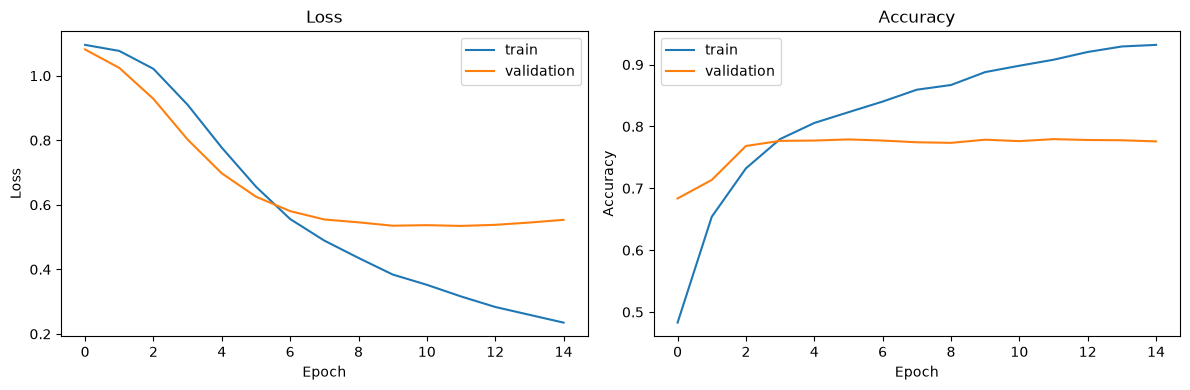

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
plt.tight_layout()
plt.savefig("figuras/curvas_mlp.png", dpi=150, bbox_inches="tight")
plt.show()

Test loss: 0.5336
Test accuracy: 0.7818
              precision    recall  f1-score   support

    negative       0.88      0.83      0.85      1363
     neutral       0.60      0.65      0.62       460
    positive       0.70      0.77      0.73       345

    accuracy                           0.78      2168
   macro avg       0.72      0.75      0.74      2168
weighted avg       0.79      0.78      0.79      2168



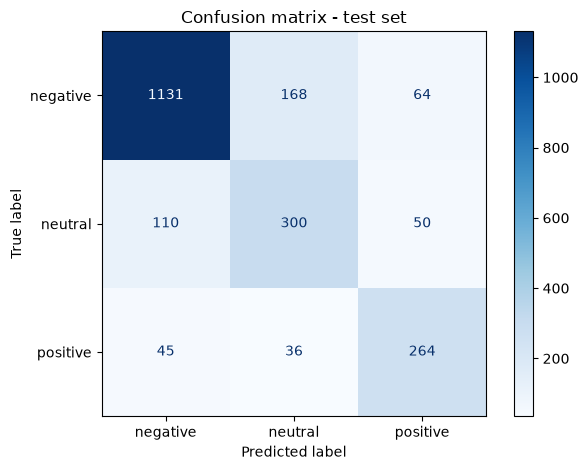

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
test_probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probabilities, axis=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap="Blues", values_format="d"
)
plt.title("Confusion matrix - test set")
plt.tight_layout()
plt.savefig("figuras/matriz_confusion_mlp.png", dpi=150, bbox_inches="tight")
plt.show()

## Predicción de un tweet nuevo

In [6]:
def predict_sentiment(tweet):
    """Return the sentiment prediction and its probability for each class."""
    cleaned_tweet = limpiar(tweet)
    features = tfidf.transform([cleaned_tweet]).toarray().astype(np.float32)
    probabilities = model.predict(features, verbose=0)[0]
    predicted_class = class_names[int(np.argmax(probabilities))]
    return predicted_class, dict(zip(class_names, probabilities.tolist()))


example_tweet = "The flight was on time and the crew was very helpful!"
sentiment, probabilities = predict_sentiment(example_tweet)
print("Predicted sentiment:", sentiment)
print("Probabilities:", probabilities)

Predicted sentiment: positive
Probabilities: {'negative': 0.06790059059858322, 'neutral': 0.02794632688164711, 'positive': 0.9041531085968018}


In [7]:
import pandas as pd
from sklearn.metrics import f1_score
from src.model import construir_mlp

configs = [
    {"hidden_units": (128, 64), "dropout": 0.3, "learning_rate": 1e-3},
    {"hidden_units": (128, 64), "dropout": 0.5, "learning_rate": 1e-3},
    {"hidden_units": (64,),     "dropout": 0.5, "learning_rate": 1e-3},
    {"hidden_units": (256, 128), "dropout": 0.5, "learning_rate": 1e-3},
    {"hidden_units": (128, 64), "dropout": 0.5, "learning_rate": 1e-4},
]
filas = []
for cfg in configs:
    tf.keras.utils.set_random_seed(SEED)
    m = construir_mlp(X_train.shape[1], **cfg)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20,
              batch_size=64, class_weight=class_weight, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(
                  monitor="val_loss", patience=3, restore_best_weights=True)])
    pred = m.predict(X_val, verbose=0).argmax(axis=1)
    filas.append({**cfg,
                  "mejor_epoca": int(np.argmin(h.history["val_loss"])) + 1,
                  "val_loss": round(min(h.history["val_loss"]), 4),
                  "val_acc": round(float((pred == y_val).mean()), 4),
                  "val_f1_macro": round(float(f1_score(y_val, pred, average="macro")), 4)})
tabla = pd.DataFrame(filas)
tabla.to_csv("data/experimentos_mlp.csv", index=False)
tabla

,hidden_units,dropout,learning_rate,mejor_epoca,val_loss,val_acc,val_f1_macro
0,"(128, 64)",0.3,0.0010,1,0.5782,0.7671,0.7212
1,"(128, 64)",0.5,0.0010,2,0.5574,0.7814,0.7266
2,"(64,)",0.5,0.0010,4,0.5406,0.7744,0.7210
3,"(256, 128)",0.5,0.0010,1,0.5699,0.7740,0.7278
4,"(128, 64)",0.5,0.0001,12,0.5346,0.7795,0.7223
